# Time Correction Visualization Pipeline

This notebook provides a step-by-step interactive visualization for evaluating **Time Correction** results.
It compares **Raw** data (Before Time Correction) with **Time-Corrected** data (After Time Correction).

In [ ]:
%load_ext autoreload
%autoreload 2
import sys
import os

# Add the project root to sys.path so we can import CyTof_BatchCorrection
project_root = os.path.dirname(os.getcwd())
if project_root not in sys.path:
    sys.path.append(project_root)
print(f"Project root added to sys.path: {project_root}")


Project root added to sys.path: d:\Private\Study\france\study\M2 Internship\Project\BatchCorrection


#### This is for the visualization of the Time-corrected results

In [ ]:
import os
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from collections import defaultdict
import collections.abc
collections.MutableMapping = collections.abc.MutableMapping
import scanpy as sc
import seaborn as sns
import anndata as ad
from matplotlib.lines import Line2D

from CyTof_BatchCorrection.utils import (
    load_config, get_config, harmonize_marker, apply_marker_schema, 
    add_metadata, assign_cell_type, enforce_schema, read_cytof_file,
    CyTOFContext, identify_shared_markers, variation_pca, arcsinh,
    generate_and_save_colors, load_and_subset_colors, plot_variance_bar
)
from CyTof_BatchCorrection.time_correction_visualization import (
    umap_by_celltype, millions_formatter, marker_trends, 
    plot_time_effect_density, plot_signal_distributions_joint,
    calculate_mwu, plot_mwu_distribution, calculate_kd, 
    plot_kd_distribution, preprocess_files, load_and_preprocess_panel_time
)
from CyTof_BatchCorrection.batch_correction_visualization import (
    variation_marker, plot_variance_marker_boxplot
)

#### Main pipline for the Time Correction Visualization

In [3]:
# 0. Load Configuration and Metadata (Reference from run_time_analysis)
project_root = os.path.dirname(os.getcwd())
config_path = os.path.join(project_root, "metadata", "meta.json")
config = get_config(config_path=config_path)
ctx = CyTOFContext(config)

# Load metadata.xlsx
metadata_path = os.path.join(project_root, "metadata", "metadata.xlsx")
metadata_df = pd.read_excel(metadata_path) if os.path.exists(metadata_path) else None

# 1. Load and Preprocess Data for a specific dataset/panel
# Update these values to the group you want to visualize
target_dataset = "D0"
target_panel = "Panel1"

df_b, df_a, markers = load_and_preprocess_panel_time(target_panel, target_dataset, ctx, verbose=True)

print(f"\n--- Processing: {target_dataset} | {target_panel} ---")
print(f"Loaded {len(df_b)} cells before and {len(df_a)} cells after correction.")
print(f"Markers used: {markers}")



--- Processing: D0 | Panel1 ---
Loaded 2630794 cells before and 2630794 cells after correction.
Markers used: ['CD45', 'DNA', 'CD44', 'CD61', 'CD38', 'CD71', 'CD45RA', 'CD14', 'CD3_CD19', 'pSTAT3', 'GOT2', 'p4EBP1', 'ACADM', 'BCL-xl', 'CALCRL', 'CD34', 'CEBPa', 'pSTAT5', 'CD123', 'CD39', 'SLC7A6', 'BCAT1', 'CytC', 'CD98', 'CD33', 'DRP1', 'BCL2', 'BCAT2', 'c-myc', 'P53', 'ATF4', 'MCL1', 'Cleaved_Casp3', 'CD133', 'PKM1', 'CD135', 'GLUT1', 'PKM2', 'CD117', 'pS6_S235-S236', 'CPT1A', 'OPA1', 'pAMPK_T172', 'pCREB_S133', 'CD68', 'cisplatin', 'MPO', 'CD36', 'CD11b']


In [4]:
# --- GENERATE & LOAD GLOBAL COLORS ---
colors_save_path = os.path.join(project_root, "metadata", "colors_dict.pkl")

if metadata_path is not None and os.path.exists(metadata_path) and not os.path.exists(colors_save_path):
    print("\n===== GENERATING GLOBAL COLORS FROM GATED DATA =====")
    metadata_df_full = pd.read_excel(metadata_path)
    all_cell_types = set()
    print("[INFO] Collecting cell types from processed files...")
    tc_dir = os.path.join(ctx.output_dir, "time_corrected")
    if os.path.exists(tc_dir):
        for f in glob(os.path.join(tc_dir, "*.csv")):
            try:
                df_temp = pd.read_csv(f, usecols=["cell_type"])
                all_cell_types.update(df_temp["cell_type"].dropna().unique())
            except: pass
    
    temp_df = metadata_df_full.copy()
    for col in ["cell_type", "panel", "plate", "sample_name"]:
        if col not in temp_df.columns:
            temp_df[col] = np.nan
    temp_df["cell_type"] = pd.Series(list(all_cell_types))
    generate_and_save_colors(df=temp_df, save_path=colors_save_path)
elif os.path.exists(colors_save_path):
    print(f"[INFO] Using existing colors from {colors_save_path}")

global_colors = {}
if os.path.exists(colors_save_path):
    with open(colors_save_path, "rb") as f_in:
        global_colors = pickle.load(f_in)
    print(f"[INFO] Global colors loaded")

# --- SUBSET COLORS FOR CURRENT PANEL ---
current_colors = {}
if global_colors and os.path.exists(colors_save_path):
    current_colors = load_and_subset_colors(df_a, colors_save_path)
    print(f"[INFO] Subset colors for {target_panel} loaded")


[INFO] Using existing colors from d:\Private\Study\france\study\M2 Internship\Project\BatchCorrection\metadata\colors_dict.pkl
[INFO] Global colors loaded
[INFO] Subset colors for Panel1 loaded


In [ ]:
# 2. PCA Variance Analysis (Selection/Single Panel)
print(f"[ANALYZE] Running variation_pca for {target_panel}...")
factors = ["plate", "sample_name", "cell_type", "Time"]
var_b = variation_pca(df_b, markers=markers, group_col="condition", info_cols=factors, panel=target_panel)
var_a = variation_pca(df_a, markers=markers, group_col="condition", info_cols=factors, panel=target_panel)

# Display variance results
print("\nVariance Results (Before Correction):")
print(var_b)
print("\nVariance Results (After Correction):")
print(var_a)


[ANALYZE] Running variation_pca for Panel1...
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.

Variance Results (Before Correction):
              plate  sample_name  cell_type      Time  Residual
adult      0.001939     0.397675   0.004349  0.000816  0.595221
healthy    0.005235     0.002079   0.245011  0.000948  0.746726
pediatric  0.003322     0.060884   0.058019  0.000483  0.877292

Variance Results (After Correction):
              plate  sample_name  cell_type      Time  Residual
adult      0.001935     0.397799   0.004202  0.001489  0.594575
healthy    0.005088     0.001967   0.237928  0.001806  0.753210
pediatric  0.003179  

[ANALYZE] Generating UMAP...
Using 49 markers for UMAP: ['CD45', 'DNA', 'CD44', 'CD61', 'CD38', 'CD71', 'CD45RA', 'CD14', 'CD3_CD19', 'pSTAT3', 'GOT2', 'p4EBP1', 'ACADM', 'BCL-xl', 'CALCRL', 'CD34', 'CEBPa', 'pSTAT5', 'CD123', 'CD39', 'SLC7A6', 'BCAT1', 'CytC', 'CD98', 'CD33', 'DRP1', 'BCL2', 'BCAT2', 'c-myc', 'P53', 'ATF4', 'MCL1', 'Cleaved_Casp3', 'CD133', 'PKM1', 'CD135', 'GLUT1', 'PKM2', 'CD117', 'pS6_S235-S236', 'CPT1A', 'OPA1', 'pAMPK_T172', 'pCREB_S133', 'CD68', 'cisplatin', 'MPO', 'CD36', 'CD11b']


d:\Software\miniConda\miniConda\envs\Internship\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Software\miniConda\miniConda\envs\Internship\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
d:\Software\miniConda\miniConda\envs\Internship\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


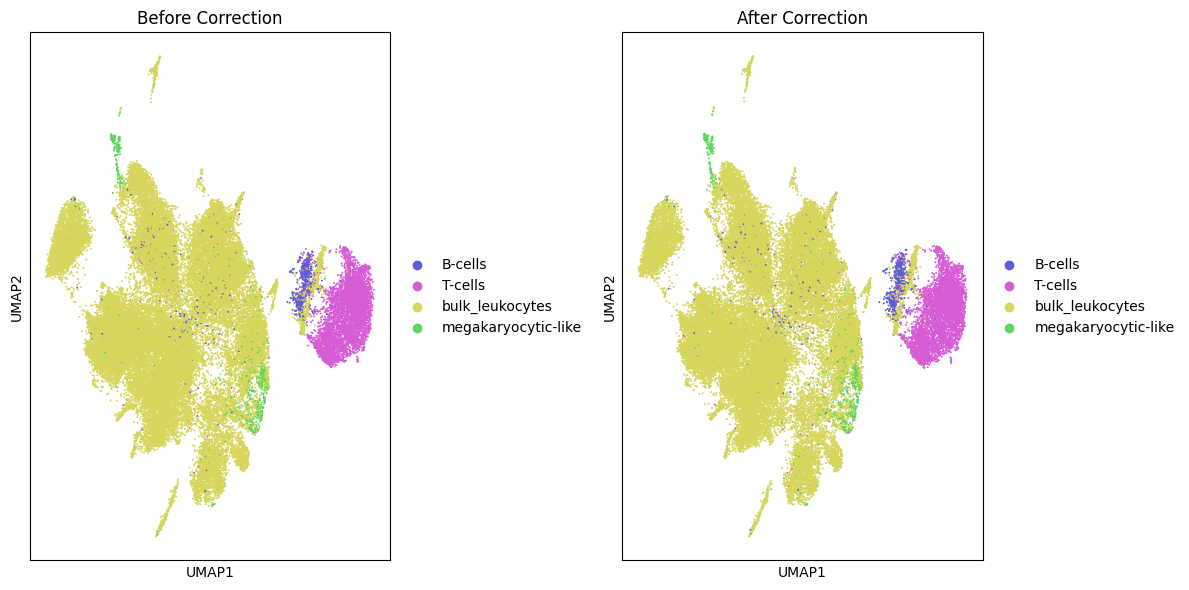

In [ ]:
# 3. UMAP
print(f"[ANALYZE] Generating UMAP...")
adata = umap_by_celltype(df_b, df_a, panel=target_panel, markers=markers, celltype_col="cell_type", subsample=50000, colors_dict=current_colors)
plt.show()


In [ ]:
# 4. Time Effect Density & Signal Distributions
# Can replace markers to the markers you are interested in visualizing
print(f"[ANALYZE] Running plot_time_effect_density...")
plot_time_effect_density(before_df=df_b, after_df=df_a, 
                            panel=target_panel, markers=markers, save_dir=None, subsample=2000000)
plt.show()

[ANALYZE] Running signal distribution plots...


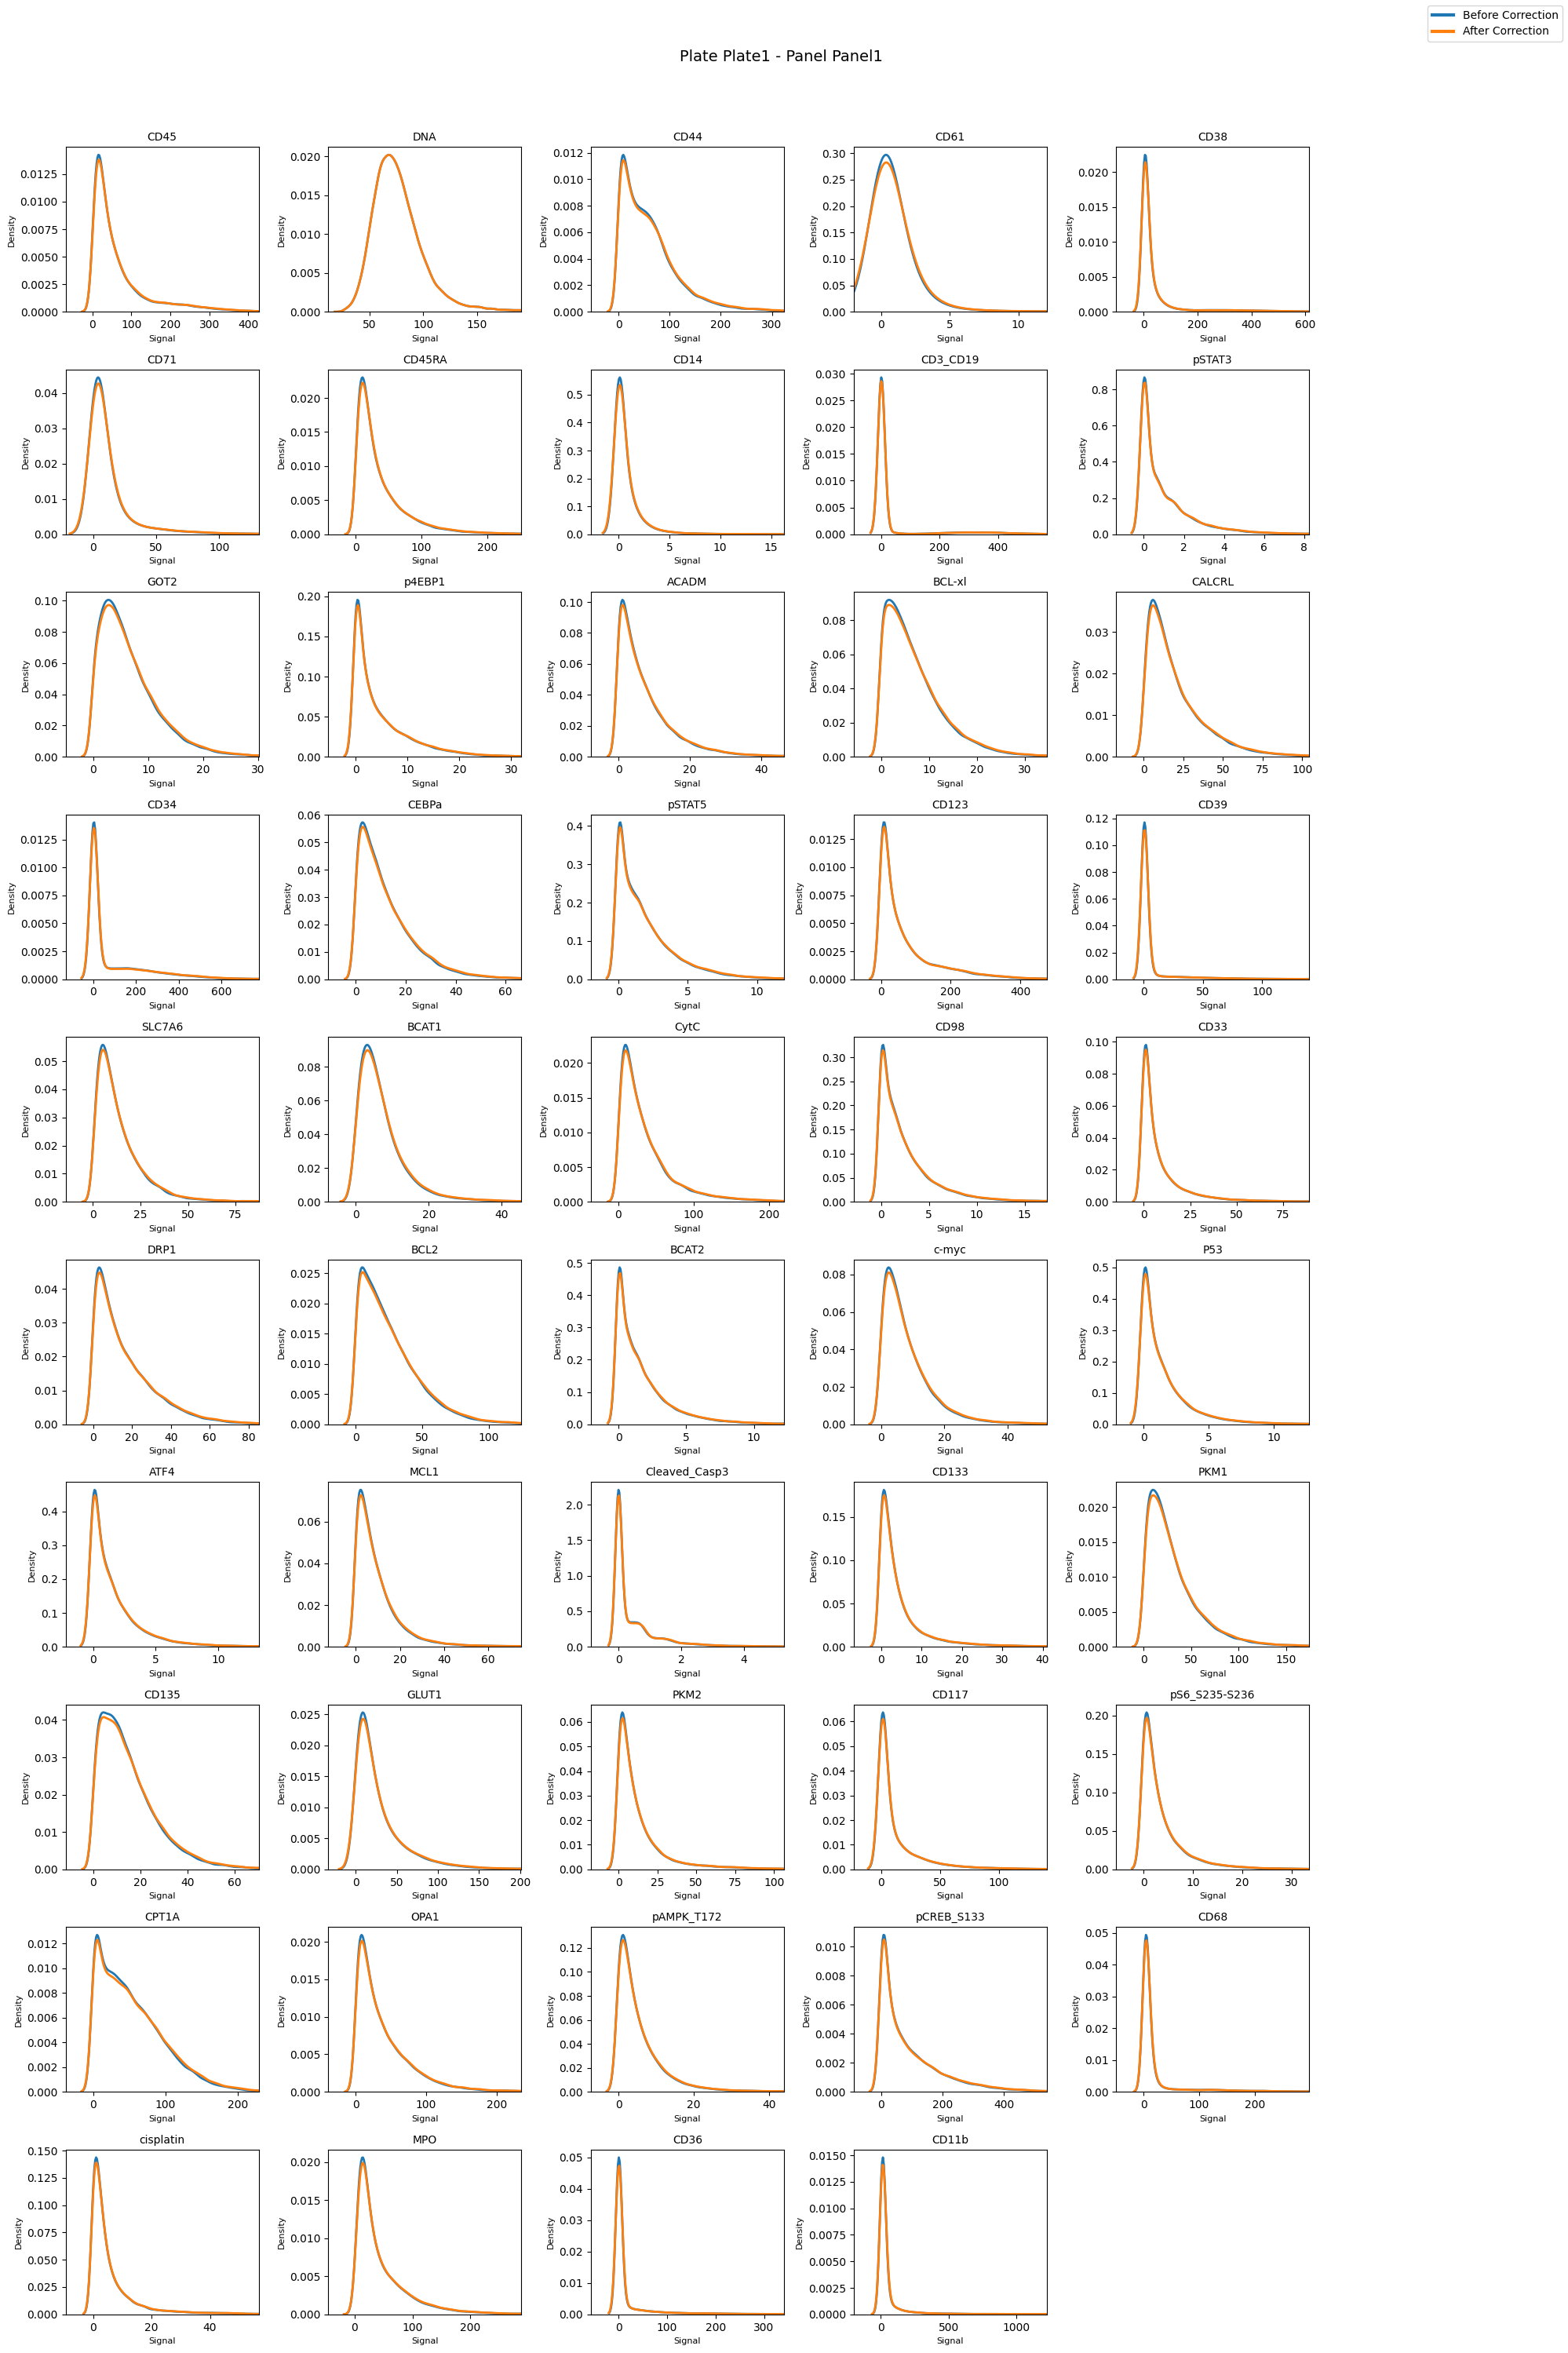

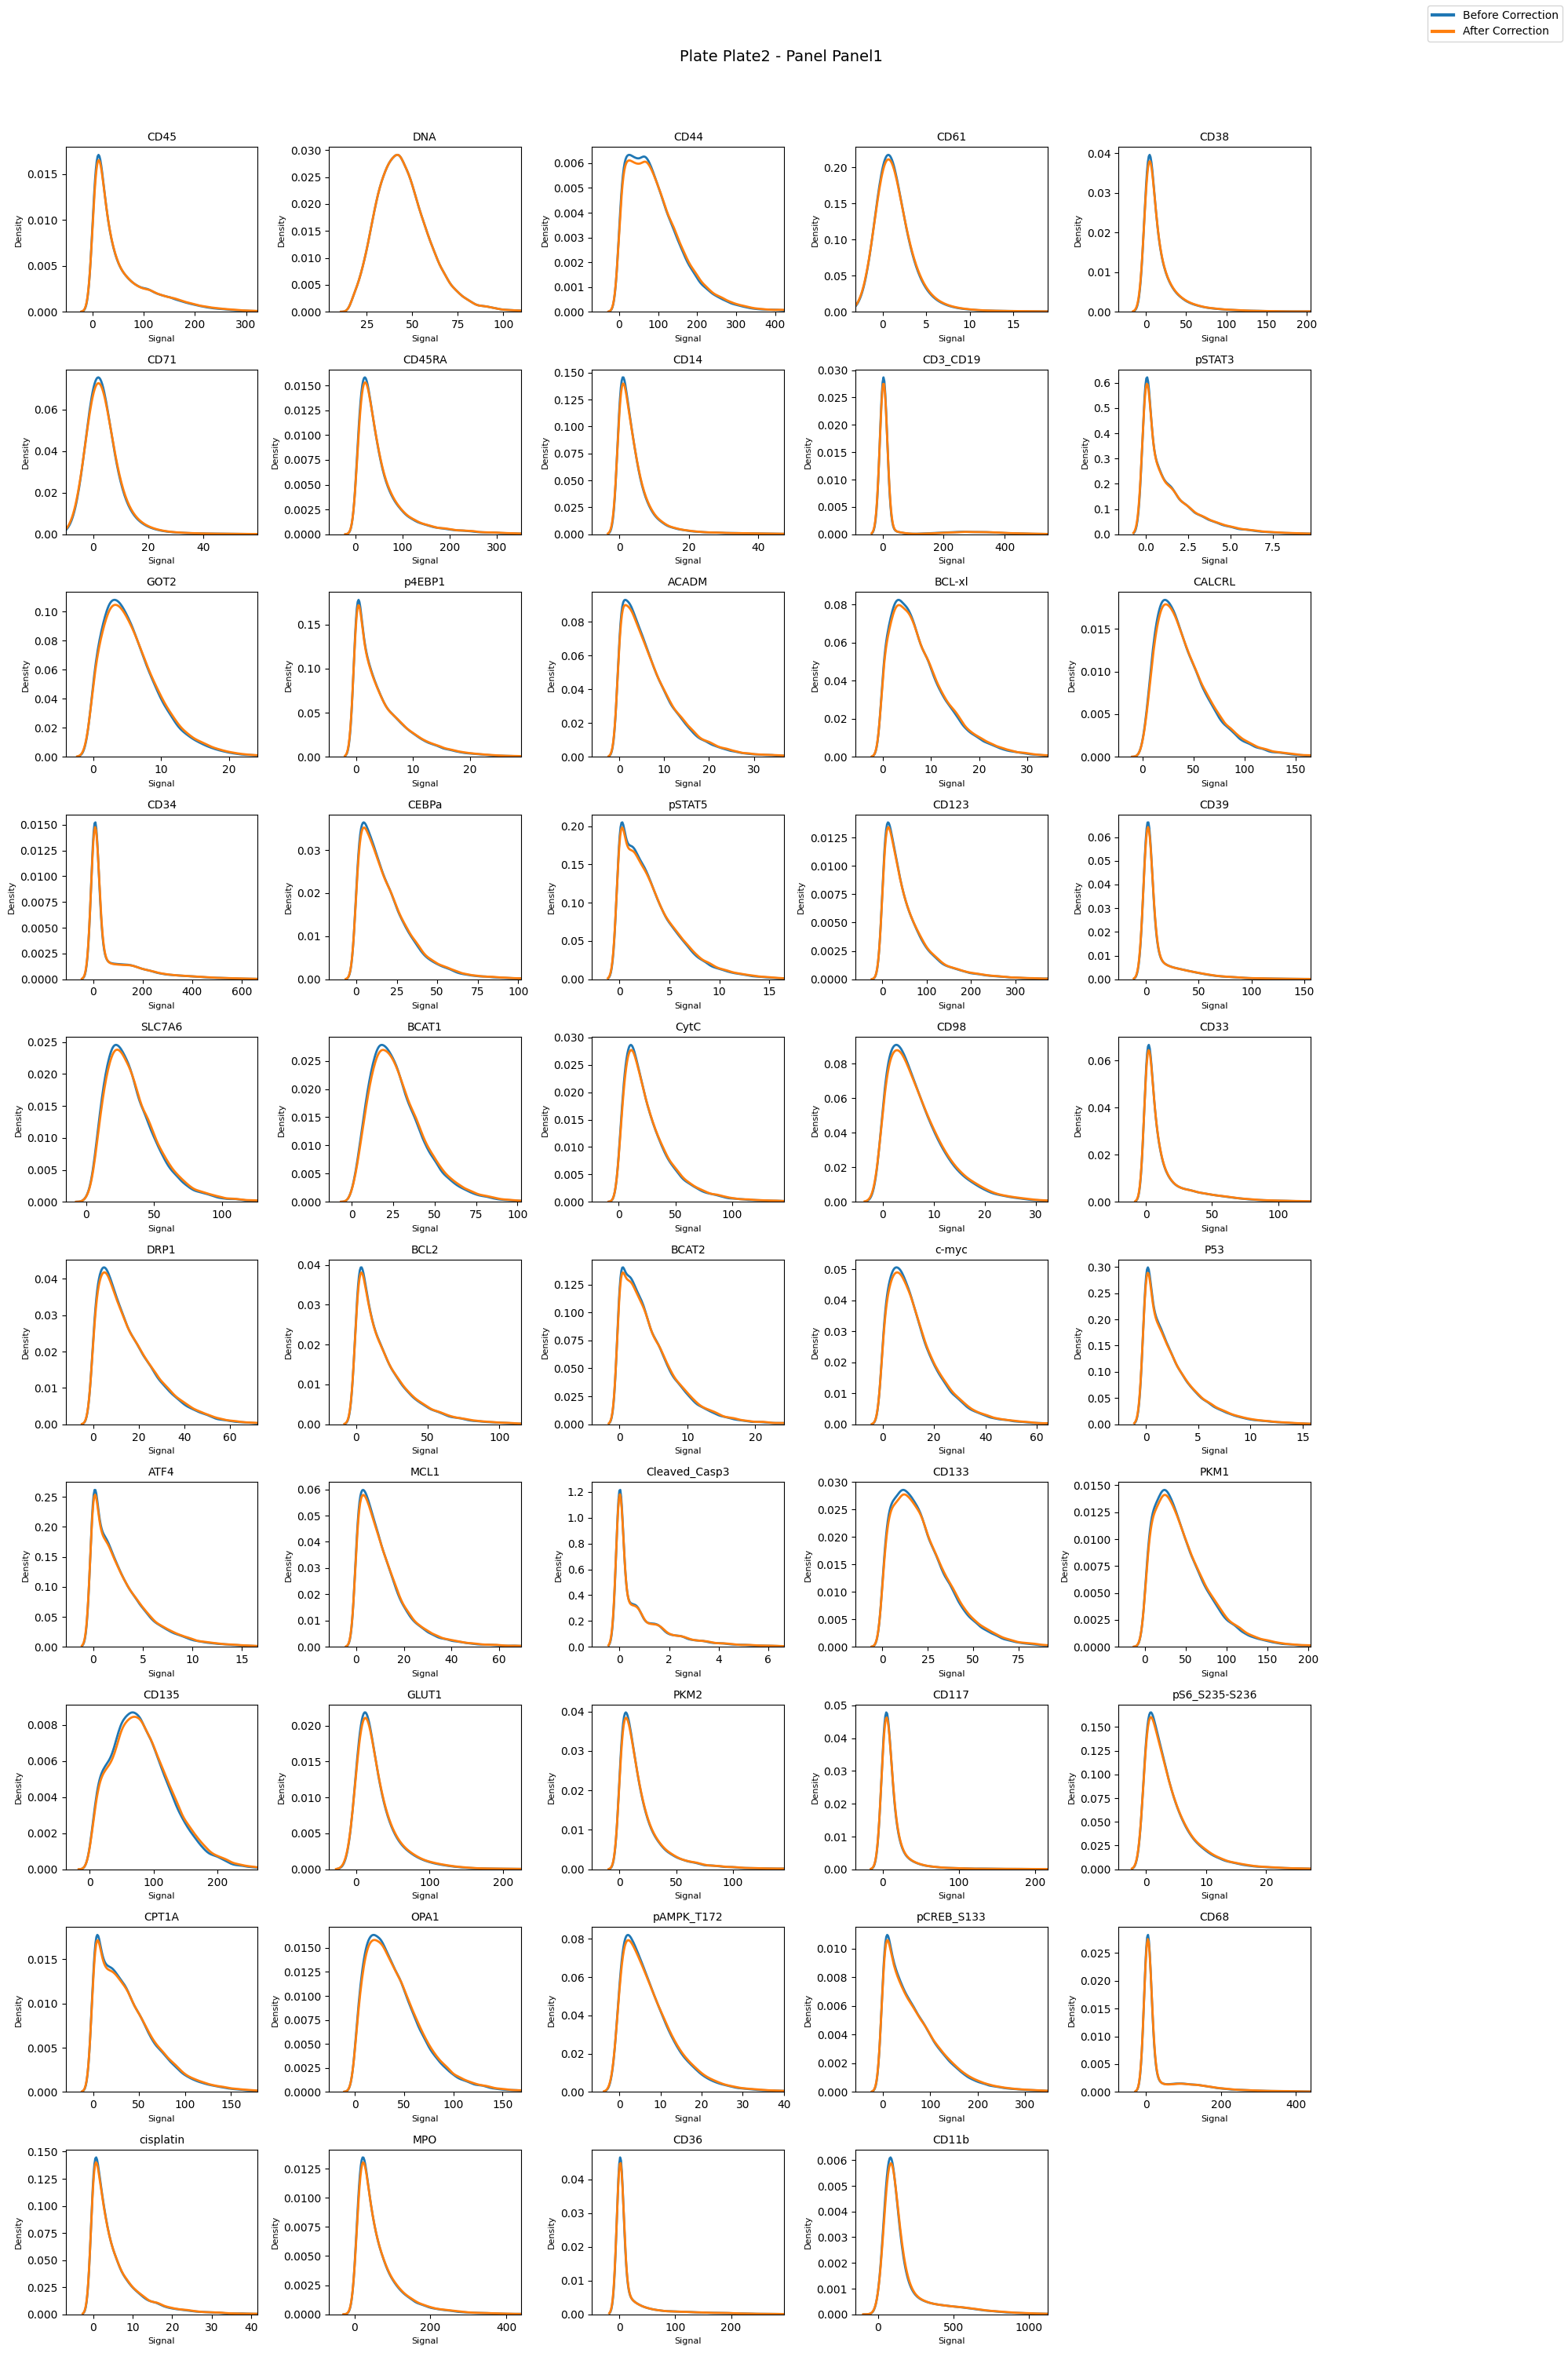

In [6]:
print(f"[ANALYZE] Running signal distribution plots...")
plot_signal_distributions_joint(df_before=df_b, df_after=df_a, panel=target_panel, markers=markers, save_dir=None, subsample=50000)
plt.show()

In [ ]:
# 5. Stats Calculation KL
print(f"[ANALYZE] Calculating stats KL...")
kd_df = calculate_kd(df_before=df_b, df_after=df_a, panel=target_panel, ctx=ctx)
plot_kd_distribution(kd_df, save_path=None)
plt.show()

In [ ]:
# 5.1 Marker-level Variance Analysis (Boxplot)
# This visualization compares the variance of each marker before and after Time Correction.
# Each dot in the boxplot represents one marker.

print(f"\n[ANALYZE] Generating Marker-level variance boxplots (Time)...")

# 1. Define output path (Consistent with pipeline.py)
base_panel_dir = os.path.join(ctx.output_dir, target_dataset, target_panel)
path_Variance = os.path.join(base_panel_dir, "Time_Variance")
os.makedirs(path_Variance, exist_ok=True)

# 2. Calculate per-marker variance
factors = [c for c in ["plate", "sample_name", "cell_type", "Time"] if c in df_b.columns]

if 'df_b' in locals() and 'df_a' in locals():
    mvar_b = variation_marker(df_b, markers=markers, group_col=None, info_cols=factors, panel=target_panel)
    mvar_a = variation_marker(df_a, markers=markers, group_col=None, info_cols=factors, panel=target_panel)
    
    # 3. Save raw data and plot (Consistent with pipeline.py)
    mvar_b.to_csv(os.path.join(path_Variance, f"variance_marker_raw_before_{target_dataset}_{target_panel}_Time.csv"), index=False)
    mvar_a.to_csv(os.path.join(path_Variance, f"variance_marker_raw_after_{target_dataset}_{target_panel}_Time.csv"), index=False)
    
    plot_variance_marker_boxplot(
        var_marker_raw=mvar_b, 
        var_marker_corr=mvar_a, 
        save_path=os.path.join(path_Variance, f"variance_marker_boxplot_{target_dataset}_{target_panel}_Time.png"), 
        use_log=True
    )
    plt.show()
else:
    print("[WARN] Dataframes df_b / df_a not found. Please run Step 1 first.")


[ANALYZE] Memory-Safe PCA for Panel1...
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.

[ANALYZE] Memory-Safe PCA for Panel2...
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.
  [INFO] Subsampling adult to 200000 cells for PCA memory safety.
  [INFO] Subsampling healthy to 200000 cells for PCA memory safety.
  [INFO] Subsampling pediatric to 200000 cells for PCA memory safety.

[POST-PROCESS] Generating cross-panel variance plot: Panel1 vs Panel2


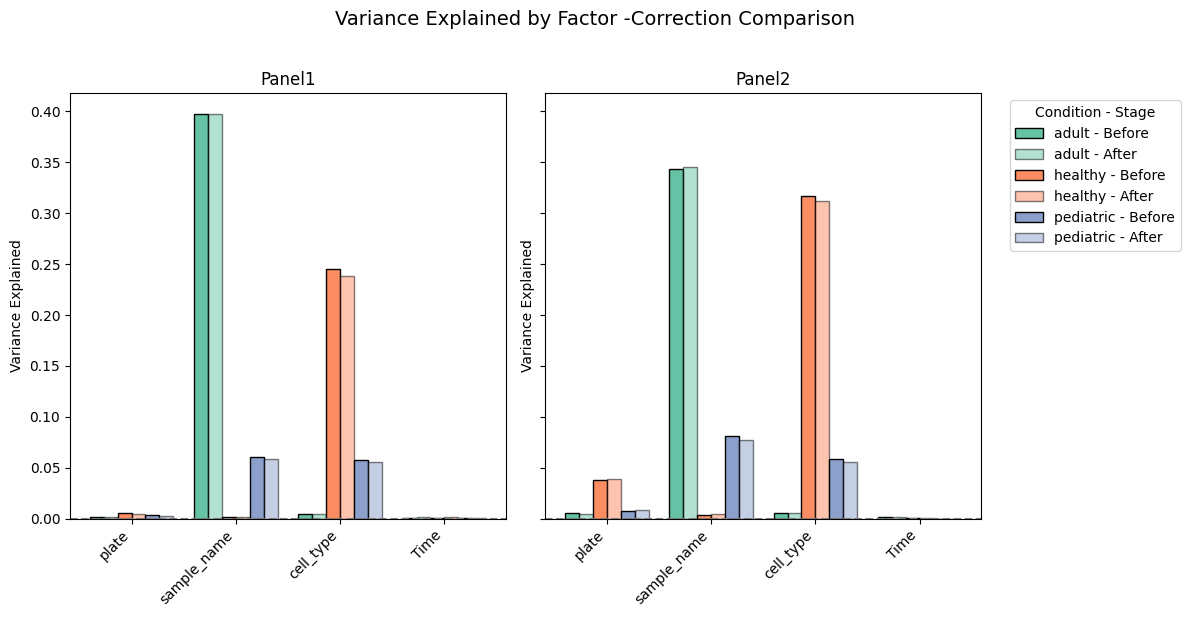

In [5]:
import gc

# 6. Cross-Panel Variance Analysis (Memory-Safe)

factors = ["plate", "sample_name", "cell_type", "Time"]

# --- Step 6.1: Cleanup current session to free space ---
try:
    del df_b, df_a, adata
except NameError:
    pass
gc.collect()

# --- Step 6.2: Process Panel 1 ---
p1_name = "Panel1"
print(f"\n[ANALYZE] Memory-Safe PCA for {p1_name}...")
df_p1_b, df_p1_a, markers_p1 = load_and_preprocess_panel_time(p1_name, target_dataset, ctx, verbose=False)

# Perform calculation
var_p1_b = variation_pca(df_p1_b, markers=markers_p1, group_col="condition", info_cols=factors, panel=p1_name)
var_p1_a = variation_pca(df_p1_a, markers=markers_p1, group_col="condition", info_cols=factors, panel=p1_name)

# CRITICAL: Delete large DataFrames to free RAM before next panel
del df_p1_b, df_p1_a
gc.collect() 

# --- Step 6.3: Process Panel 2 ---
p2_name = "Panel2"
print(f"\n[ANALYZE] Memory-Safe PCA for {p2_name}...")
df_p2_b, df_p2_a, markers_p2 = load_and_preprocess_panel_time(p2_name, target_dataset, ctx, verbose=False)

# Perform calculation
var_p2_b = variation_pca(df_p2_b, markers=markers_p2, group_col="condition", info_cols=factors, panel=p2_name)
var_p2_a = variation_pca(df_p2_a, markers=markers_p2, group_col="condition", info_cols=factors, panel=p2_name)

# Delete Panel 2 data
del df_p2_b, df_p2_a
gc.collect()

# --- Step 6.4: Cross-Panel Visualization ---
# Now we only have the small results tables (var_p1, var_p2) in memory
print(f"\n[POST-PROCESS] Generating cross-panel variance plot: {p1_name} vs {p2_name}")
plot_variance_bar(var_p1_b, var_p1_a, var_p2_b, var_p2_a)
plt.show()
